<a href="https://colab.research.google.com/github/kimdesok/Computational_Pathology_on_Graphcore_IPU/blob/main/Evaluate_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
from torchvision import models

import pandas as pd
from pathlib import Path
from datasets import load_from_disk, load_dataset
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.models as models

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

# Import your existing non-pipelined model classes here
# from models import ResNetCamelyon, ViTCamelyon
from google.colab import drive
drive.mount('/content/drive')

# -------------------------------------------------------
# Configuration
# -------------------------------------------------------
DATASET_NAME = "wltjr1007/Camelyon17-WILDS"
MODEL_DIR = "/content/drive/MyDrive/came17"

BATCH_SIZE = 64
NUM_WORKERS = 2
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

RESNET_MODELS = {
    "resnet18": (models.resnet18, models.ResNet18_Weights.IMAGENET1K_V1),
    "resnet34": (models.resnet34, models.ResNet34_Weights.IMAGENET1K_V1),
    "resnet50": (models.resnet50, models.ResNet50_Weights.IMAGENET1K_V2),
}

MODEL_NAMES = {
    "resnet18": "resnet18",
    "resnet34": "resnet34",
    "resnet50": "resnet50",
    "vit_tiny": "vit_tiny_patch16_224",
    "vit_small": "vit_small_patch16_224",
    "vit_base": "vit_base_patch16_224",
}

# -------------------------------------------------------
# Test dataset
# -------------------------------------------------------
class CamelyonTestDataset(Dataset):
    def __init__(self, dataset, transform):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        sample = self.dataset[idx]
        image = sample["image"].convert("RGB")
        label = int(sample["label"])
        return self.transform(image), label


def get_test_loader(dataset_name):
    test_dataset = load_dataset(dataset_name, split="test")

    my_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )
    ])

    test_dataset = CamelyonTestDataset(test_dataset, my_transform)

    return DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        drop_last=False,
        pin_memory=(DEVICE.type == "cuda")
    )

def create_resnet(model_name, num_classes=2, pretrained=True):
    if model_name not in RESNET_MODELS:
        raise ValueError(f"Unsupported ResNet: {model_name}")
    constructor, weights = RESNET_MODELS[model_name]
    backbone = constructor(weights=weights if pretrained else None)
    backbone.fc = nn.Linear(backbone.fc.in_features, num_classes)
    return backbone

class ResNetCamelyon(nn.Module):
    def __init__(self, model_name="resnet18", num_classes=2, pretrained=True):
        super().__init__()
        self.backbone = create_resnet(model_name, num_classes, pretrained)

    def forward(self, x, labels=None):
        x = x.to(self.backbone.conv1.weight.dtype)
        logits = self.backbone(x)

        if labels is None:
            return logits
        return logits, F.cross_entropy(logits.float(), labels)

class ViTCamelyon(nn.Module):
    def __init__(self, model_name=None, num_classes=2, pretrained=True, drop_path_rate=0.1):
        super().__init__()
        self.backbone = timm.create_model(
            model_name,
            pretrained=pretrained,
            num_classes=num_classes,
            drop_path_rate=drop_path_rate
        )

    def forward(self, x, labels=None):
        x = x.to(self.backbone.patch_embed.proj.weight.dtype)
        logits = self.backbone(x)

        if labels is None:
            return logits

        loss = torch.nn.functional.cross_entropy(logits.float(), labels)
        return logits, loss

# -------------------------------------------------------
# Identify architecture and load checkpoint
# -------------------------------------------------------
def load_model(checkpoint_path):
    filename = checkpoint_path.name.lower()

    model_name = next(
        (name for prefix, name in MODEL_NAMES.items()
         if filename.startswith(prefix)),
        None
    )

    if model_name is None:
        raise ValueError(f"Unknown model architecture: {filename}")

    if model_name.startswith("resnet"):
        model = ResNetCamelyon(model_name, pretrained=False)
    else:
        model = ViTCamelyon(model_name, pretrained=False)

    state_dict = torch.load(checkpoint_path, map_location="cpu")
    model.load_state_dict(state_dict, strict=True)

    model = model.float().to(DEVICE)
    model.eval()

    return model

# -------------------------------------------------------
# Evaluate one model
# -------------------------------------------------------
def evaluate_model(model, test_loader):
    predictions, probability, true_labels = [], [], []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(DEVICE).float()

            logits = model(images).float()
            probs = torch.softmax(logits, dim=1)
            preds = torch.argmax(logits, dim=1)

            predictions.extend(preds.cpu().tolist())
            probability.extend(probs[:, 1].cpu().tolist())
            true_labels.extend(labels.cpu().tolist())

    return {
        "accuracy": accuracy_score(true_labels, predictions),
        "precision": precision_score(
            true_labels, predictions, average="weighted", zero_division=0
        ),
        "recall": recall_score(
            true_labels, predictions, average="weighted", zero_division=0
        ),
        "f1_score": f1_score(
            true_labels, predictions, average="weighted", zero_division=0
        ),
        "roc_auc": roc_auc_score(true_labels, probability)
    }

# -------------------------------------------------------
# Main
# -------------------------------------------------------
def main():

    test_loader = get_test_loader(DATASET_NAME)

    checkpoint_list = sorted(Path(MODEL_DIR).glob("*.pt"))

    print(f"Device          : {DEVICE}")
    print(f"Dataset         : {DATASET_NAME}")
    print(f"Test samples    : {len(test_loader.dataset)}")
    print(f"Models found    : {len(checkpoint_list)}")

    if not checkpoint_list:
        print("No model checkpoints found.")
        return

    name_width = max(20, max(len(p.stem) for p in checkpoint_list))
    line_width = name_width + 60

    print("-" * line_width)
    print(
        f"{'Model name':<{name_width}} | "
        f"{'Accuracy':>9} {'Precision':>9} {'Recall':>9} "
        f"{'F1-score':>9} {'ROC-AUC':>9}"
    )
    print("-" * line_width)

    results = []

    for checkpoint_path in checkpoint_list:
        model = None

        try:
            model = load_model(checkpoint_path)
            metrics = evaluate_model(model, test_loader)

            print(
                f"{checkpoint_path.stem:<{name_width}} | "
                f"{metrics['accuracy']:9.4f} "
                f"{metrics['precision']:9.4f} "
                f"{metrics['recall']:9.4f} "
                f"{metrics['f1_score']:9.4f} "
                f"{metrics['roc_auc']:9.4f}",
                flush=True
            )

            results.append({
                "model_name": checkpoint_path.name,
                **metrics
            })

        except Exception as e:
            print(f"{checkpoint_path.name} | FAILED: {e}", flush=True)

        finally:
            del model
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()

    print("-" * line_width)

    if results:
        csv_path = Path(MODEL_DIR) / "test_performance.csv"
        pd.DataFrame(results).to_csv(
            csv_path, index=False, float_format="%.4f"
        )
        print(f"Results saved to: {csv_path}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


README.md:   0%|          | 0.00/1.43k [00:00<?, ?B/s]

data/train-00000-of-00014.parquet: reconstructing file:   0%|          |  0.00B /  470MB            

data/train-00000-of-00014.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00014.parquet: reconstructing file:   0%|          |  0.00B /  469MB            

data/train-00001-of-00014.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00014.parquet: reconstructing file:   0%|          |  0.00B /  489MB            

... (37 outputs left out)

Generating train split:   0%|          | 0/302436 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/68464 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/85054 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'label', 'center', 'image_id', 'patient', 'node', 'x_coord', 'y_coord', 'slide'],
    num_rows: 85054
})
['image', 'label', 'center', 'image_id', 'patient', 'node', 'x_coord', 'y_coord', 'slide']
Test samples: 85054
First label: 0


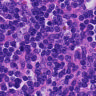

In [2]:
# Verify the dataset before evaluating all models
import os

def load_camelyon(dataset_name, dataset_path):
    if os.path.exists(dataset_path) :
        print("Loading dataset from local disk...")
        return load_from_disk(dataset_path)
    print("Local data not found. Downloading from Hugging Face...")
    ds = load_dataset(dataset_name, cache_dir=dataset_path)
    ds.save_to_disk(dataset_path)
    return ds

DATASET_PATH ="/content/drive/MyDrive/datasets/camelyon17_wilds_test"

ds = load_camelyon(DATASET_NAME, DATASET_PATH)

print(ds)
print(ds.column_names)
print("Test samples:", len(ds))
print("First label:", ds[0]["label"])

display(ds[0]["image"])

In [3]:
!nvidia-smi

Tue Nov 24 06:35:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [7]:
print("Device:", DEVICE)
print("Test samples:", len(ds))
print("Models found:", len(list(Path(MODEL_DIR).glob("*.pt"))))

Device: cuda
Test samples: 85054
Models found: 4


In [8]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [9]:
print("PyTorch version:", torch.__version__)
print("CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

PyTorch version: 2.14.1+cu130
CUDA version: 13.0
CUDA available: True
GPU count: 1


In [14]:
if __name__ == "__main__":
    main()

Device          : cuda
Dataset         : wltjr1007/Camelyon17-WILDS
Test samples    : 85054
Models found    : 4
--------------------------------------------------------------------------------------------------------------------------------------
Model name                                                                 |  Accuracy Precision    Recall  F1-score   ROC-AUC
--------------------------------------------------------------------------------------------------------------------------------------
resnet50_bs4_lr5e-06_rf1_di4_ga8_Camelyon17-WILDS_20261120_205255_722248   |    0.8440    0.8793    0.8440    0.8403    0.9633
vit_base_bs1_lr5e-06_rf1_di8_ga32_Camelyon17-WILDS_20261114_163000_576482  |    0.9619    0.9633    0.9619    0.9618    0.9939
vit_small_bs4_lr5e-06_rf1_di8_ga32_Camelyon17-WILDS_20261028_050010_764721 |    0.9619    0.9619    0.9619    0.9619    0.9923
vit_tiny_bs1_lr5e-06_rf1_di8_ga32_Camelyon17-WILDS_20261123_212814_660748  |    0.9141    0.9216    0.9141    